# Hotel Booking Cancellation Prediction

Predicting whether a hotel booking will be **canceled**, using Logistic Regression, Random Forest and
Gradient Boosting, with careful handling of **data leakage**, duplicate records, missing values,
feature engineering, threshold analysis and permutation-based feature importance.

**Dataset:** Hotel Booking Demand (Resort Hotel and City Hotel, 2015–2017)


## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
os.makedirs("visuals", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Libraries imported and output folders ready!")

Libraries imported and output folders ready!


## 2. Load Dataset

In [2]:
df = pd.read_csv("hotel_bookings.csv")
print("Shape:", df.shape)

Shape: (119390, 32)


## 3. Data Overview

In [3]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [5]:
print("Target distribution (is_canceled):")
print(df["is_canceled"].value_counts())
print()
print((df["is_canceled"].value_counts(normalize=True) * 100).round(2))

Target distribution (is_canceled):
is_canceled
0    75166
1    44224
Name: count, dtype: int64

is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


## 4. Data Cleaning

### 4.1 Missing Values

In [6]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2)
})
missing[missing["Missing Count"] > 0].sort_values("Missing Count", ascending=False)

,Missing Count,Missing %
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


### 4.2 Duplicate Records

In [7]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 31994
Shape after removing duplicates: (87396, 32)


### 4.3 Removing Data Leakage

Some columns would not be known at the time a booking is made, or directly reveal the outcome:

- `reservation_status` and `reservation_status_date` — they literally state whether the booking was
  canceled or checked out. Keeping them would make the model look perfect while being useless in practice.
- `assigned_room_type` — assigned at or after check-in, so it is not available when predicting cancellation.
- `company` — about 94% missing.


In [8]:
print(pd.crosstab(df["reservation_status"], df["is_canceled"]))

is_canceled             0      1
reservation_status              
Canceled                0  23011
Check-Out           63371      0
No-Show                 0   1014


In [9]:
leakage_and_sparse_cols = [
    "reservation_status", "reservation_status_date",
    "assigned_room_type", "company"
]

df = df.drop(columns=leakage_and_sparse_cols)
print("Shape after dropping leakage/sparse columns:", df.shape)

Shape after dropping leakage/sparse columns: (87396, 28)


### 4.4 Handling Remaining Missing Values and Invalid Rows

In [10]:
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna(0).astype(int).astype(str)

# Bookings with zero guests are invalid
zero_guests = (df["adults"] + df["children"] + df["babies"]) == 0
print("Rows with zero guests:", zero_guests.sum())
df = df[~zero_guests]

# Negative average daily rate is invalid
print("Rows with negative ADR:", (df["adr"] < 0).sum())
df = df[df["adr"] >= 0].reset_index(drop=True)

print("Final shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Rows with zero guests: 166
Rows with negative ADR: 1
Final shape: (87229, 28)
Remaining missing values: 0


## 5. Feature Engineering

In [11]:
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]

df[["total_nights", "total_guests"]].describe()

,total_nights,total_guests
count,87229.000000,87229.000000
mean,3.628461,2.029107
std,2.742879,0.790146
min,0.000000,1.000000
25%,2.000000,2.000000
50%,3.000000,2.000000
75%,5.000000,2.000000
max,69.000000,55.000000


## 6. Exploratory Data Analysis (EDA)

### 6.1 Cancellation Rate by Hotel Type

hotel
City Hotel      30.10
Resort Hotel    23.48
Name: is_canceled, dtype: float64


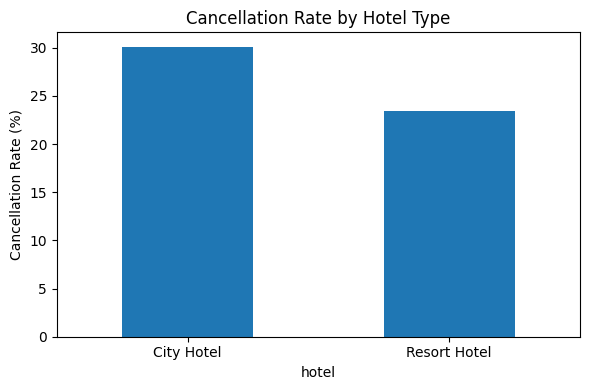

In [12]:
hotel_rate = df.groupby("hotel")["is_canceled"].mean().mul(100).round(2)
print(hotel_rate)

hotel_rate.plot(kind="bar", figsize=(6, 4))
plt.title("Cancellation Rate by Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visuals/cancellation_by_hotel.png", dpi=150)
plt.show()

### 6.2 Cancellation Rate by Deposit Type

deposit_type
No Deposit    26.72
Non Refund    94.70
Refundable    24.30
Name: is_canceled, dtype: float64


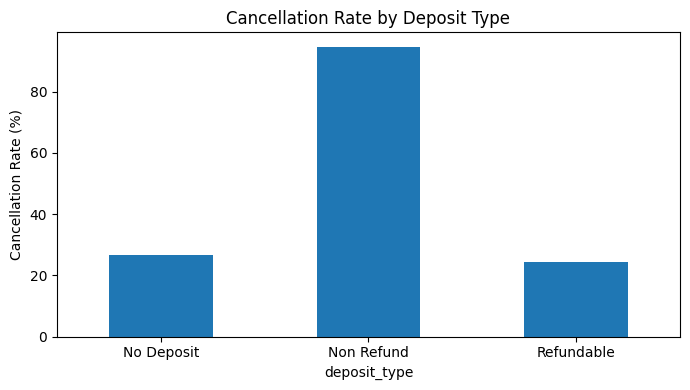

In [13]:
deposit_rate = df.groupby("deposit_type")["is_canceled"].mean().mul(100).round(2)
print(deposit_rate)

deposit_rate.plot(kind="bar", figsize=(7, 4))
plt.title("Cancellation Rate by Deposit Type")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visuals/cancellation_by_deposit_type.png", dpi=150)
plt.show()

### 6.3 Lead Time vs Cancellation

               count   mean   std  min   25%   50%    75%    max
is_canceled                                                     
0            63220.0   70.2  81.7  0.0   7.0  38.0  110.0  737.0
1            24009.0  105.7  91.8  0.0  32.0  80.0  158.0  629.0


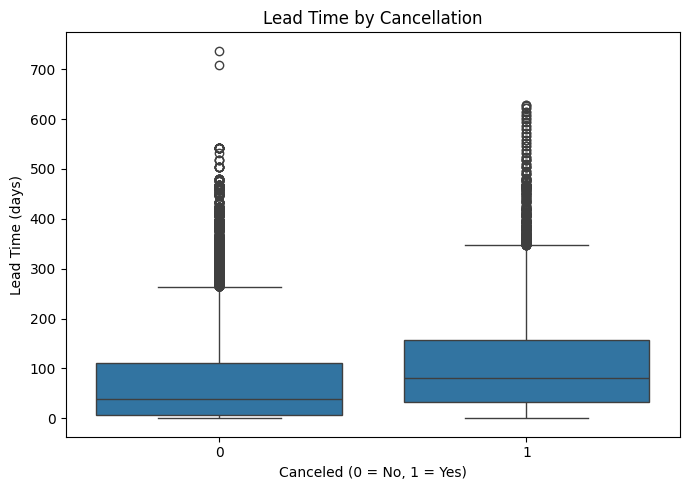

In [14]:
print(df.groupby("is_canceled")["lead_time"].describe().round(1))

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="is_canceled", y="lead_time")
plt.title("Lead Time by Cancellation")
plt.xlabel("Canceled (0 = No, 1 = Yes)")
plt.ylabel("Lead Time (days)")
plt.tight_layout()
plt.savefig("visuals/lead_time_vs_cancellation.png", dpi=150)
plt.show()

### 6.4 Cancellation Rate by Market Segment

market_segment
Undefined        100.00
Online TA         35.38
Groups            27.07
Aviation          19.91
Offline TA/TO     14.85
Direct            14.75
Complementary     12.28
Corporate         12.12
Name: is_canceled, dtype: float64


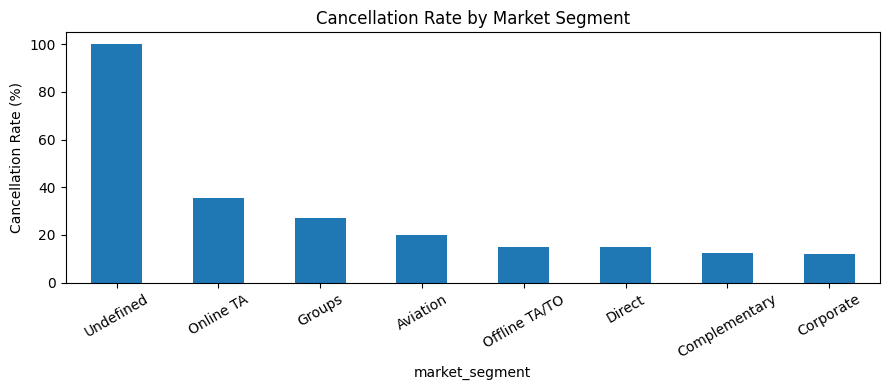

In [15]:
segment_rate = (
    df.groupby("market_segment")["is_canceled"].mean().mul(100).round(2)
    .sort_values(ascending=False)
)
print(segment_rate)

segment_rate.plot(kind="bar", figsize=(9, 4))
plt.title("Cancellation Rate by Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("visuals/cancellation_by_market_segment.png", dpi=150)
plt.show()

### 6.5 Cancellation Rate by Arrival Month

arrival_date_month
January      22.13
February     23.21
March        24.43
April        30.46
May          29.27
June         30.34
July         31.82
August       32.22
September    24.56
October      23.72
November     21.15
December     26.94
Name: is_canceled, dtype: float64


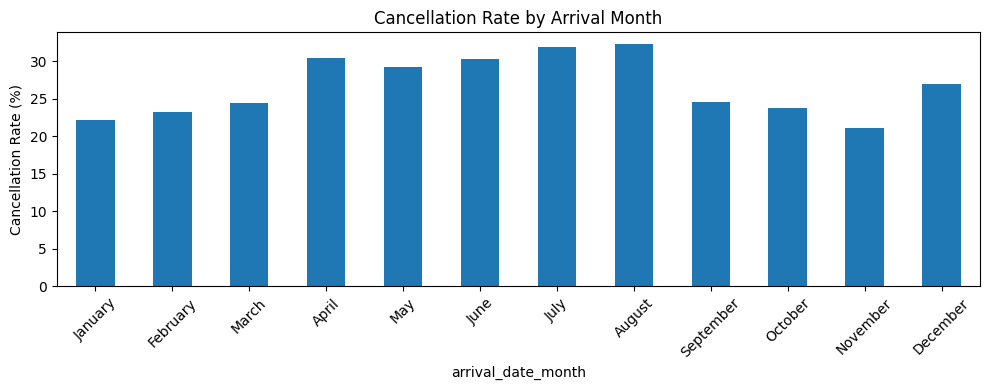

In [16]:
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

month_rate = (
    df.groupby("arrival_date_month")["is_canceled"].mean().mul(100)
    .reindex(month_order).round(2)
)
print(month_rate)

month_rate.plot(kind="bar", figsize=(10, 4))
plt.title("Cancellation Rate by Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("visuals/cancellation_by_month.png", dpi=150)
plt.show()

### 6.6 Special Requests and Previous Cancellations

In [17]:
print("Cancellation rate by number of special requests:")
print(df.groupby("total_of_special_requests")["is_canceled"].mean().mul(100).round(2))

print("\nCancellation rate by whether the guest canceled before:")
print(
    df.groupby(df["previous_cancellations"] > 0)["is_canceled"]
      .mean().mul(100).round(2)
)

Cancellation rate by number of special requests:
total_of_special_requests
0    33.25
1    22.44
2    21.32
3    17.11
4    10.62
5     5.56
Name: is_canceled, dtype: float64

Cancellation rate by whether the guest canceled before:
previous_cancellations
False    26.73
True     68.00
Name: is_canceled, dtype: float64


## 7. Prepare Features and Target

In [18]:
numeric_features = [
    "lead_time", "arrival_date_year", "arrival_date_week_number",
    "arrival_date_day_of_month", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "is_repeated_guest",
    "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
    "days_in_waiting_list", "adr", "required_car_parking_spaces",
    "total_of_special_requests", "total_nights", "total_guests"
]

categorical_features = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment",
    "distribution_channel", "reserved_room_type", "deposit_type",
    "agent", "customer_type"
]

features = numeric_features + categorical_features

X = df[features]
y = df["is_canceled"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (87229, 29)
y shape: (87229,)


## 8. Train-Test Split

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (69783, 29)
X_test : (17446, 29)


## 9. Preprocessing Pipeline

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=100,
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

## 10. Model Comparison (Cross-Validation)

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=42
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

cv_summary = []

for name, model in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])

    scores = cross_validate(
        pipe, X_train, y_train, cv=cv,
        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"]
    )

    cv_summary.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })
    print(f"{name} done")

cv_summary_df = pd.DataFrame(cv_summary)
cv_summary_df.round(4)

Logistic Regression done
Random Forest done
Gradient Boosting done


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7974,0.6756,0.5075,0.5796,0.8540
1,Random Forest,0.8438,0.7756,0.6086,0.6821,0.9092
2,Gradient Boosting,0.8440,0.7450,0.6586,0.6991,0.9108


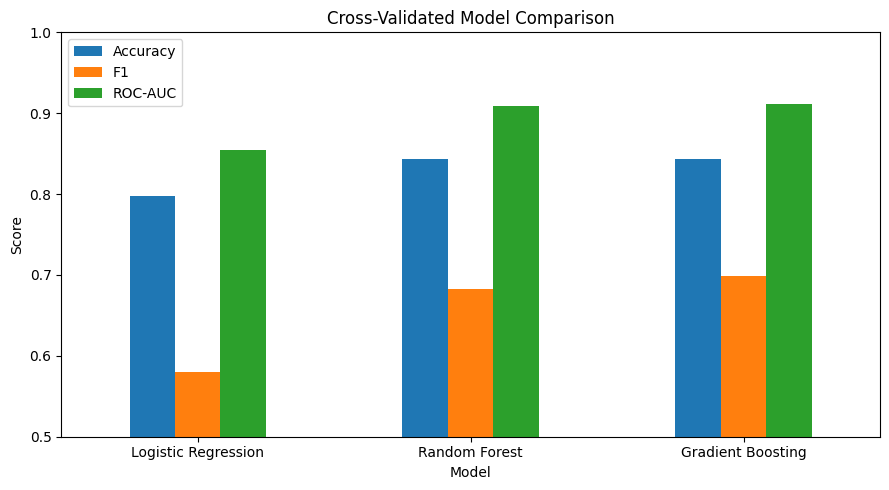

In [22]:
cv_summary_df.set_index("Model")[["Accuracy", "F1", "ROC-AUC"]].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Cross-Validated Model Comparison")
plt.ylabel("Score")
plt.ylim(0.5, 1.0)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visuals/model_comparison.png", dpi=150)
plt.show()

## 11. Hyperparameter Tuning (Gradient Boosting)

In [23]:
from sklearn.model_selection import RandomizedSearchCV

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingClassifier(max_iter=300, random_state=42))
])

param_distributions = {
    "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "model__max_depth": [None, 6, 10],
    "model__max_leaf_nodes": [31, 63, 127],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 0.1, 1.0]
}

search = RandomizedSearchCV(
    gb_pipeline, param_distributions, n_iter=8,
    cv=cv, scoring="roc_auc", random_state=42, n_jobs=-1
)

search.fit(X_train, y_train)

print("Best Parameters:")
print(search.best_params_)
print("\nBest CV ROC-AUC:", round(search.best_score_, 4))

Best Parameters:
{'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 63, 'model__max_depth': None, 'model__learning_rate': 0.03, 'model__l2_regularization': 1.0}

Best CV ROC-AUC: 0.9139


In [24]:
best_model = search.best_estimator_

## 12. Final Evaluation on the Test Set

In [25]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve
)

y_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.50).astype(int)

print("Final Test Results (threshold = 0.50)")
print("-" * 40)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_proba):.4f}")

Final Test Results (threshold = 0.50)
----------------------------------------
Accuracy : 0.8523
Precision: 0.7538
Recall   : 0.6885
F1 Score : 0.7196
ROC-AUC  : 0.9197


In [26]:
print(classification_report(y_test, y_pred, target_names=["Not Canceled", "Canceled"]))

              precision    recall  f1-score   support

Not Canceled       0.89      0.91      0.90     12644
    Canceled       0.75      0.69      0.72      4802

    accuracy                           0.85     17446
   macro avg       0.82      0.80      0.81     17446
weighted avg       0.85      0.85      0.85     17446



[[11564  1080]
 [ 1496  3306]]


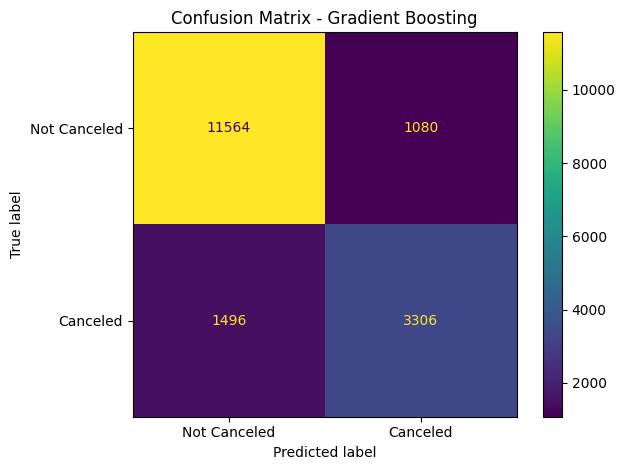

In [27]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["Not Canceled", "Canceled"]).plot()
plt.title("Confusion Matrix - Gradient Boosting")
plt.tight_layout()
plt.savefig("visuals/confusion_matrix.png", dpi=150)
plt.show()

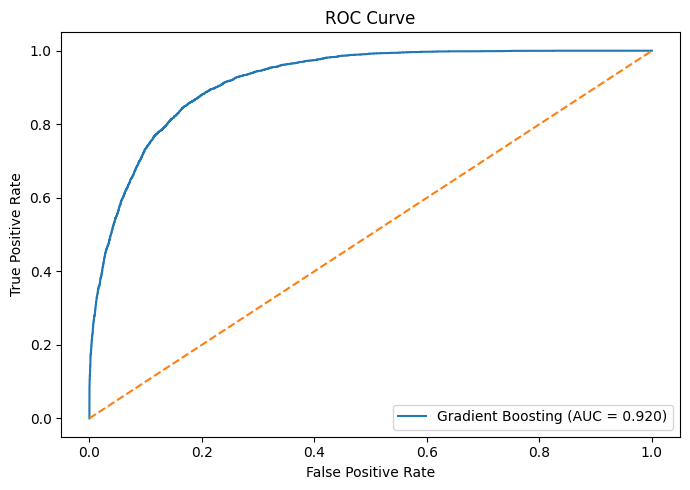

In [28]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Gradient Boosting (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig("visuals/roc_curve.png", dpi=150)
plt.show()

## 13. Decision Threshold Analysis

In [29]:
from sklearn.model_selection import cross_val_predict

cv_proba = cross_val_predict(
    best_model, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.05):
    pred = (cv_proba >= threshold).astype(int)
    threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(y_train, pred),
        "recall": recall_score(y_train, pred),
        "f1": f1_score(y_train, pred)
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(4))

best_threshold = float(threshold_df.loc[threshold_df["f1"].idxmax(), "threshold"])
print("\nBest threshold (CV F1):", best_threshold)

   threshold  precision  recall      f1
0       0.30     0.6393  0.8387  0.7256
1       0.35     0.6719  0.7973  0.7292
2       0.40     0.6982  0.7533  0.7247
3       0.45     0.7243  0.7116  0.7179
4       0.50     0.7485  0.6649  0.7042
5       0.55     0.7715  0.6198  0.6874
6       0.60     0.7963  0.5688  0.6636
7       0.65     0.8230  0.5048  0.6258
8       0.70     0.8510  0.4367  0.5772

Best threshold (CV F1): 0.35


In [30]:
y_pred_best = (y_proba >= best_threshold).astype(int)

print(f"Test Results at threshold = {best_threshold}")
print("-" * 40)
print(f"Accuracy : {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_best):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_best):.4f}")
print(confusion_matrix(y_test, y_pred_best))

Test Results at threshold = 0.35
----------------------------------------
Accuracy : 0.8429
Precision: 0.6794
Recall   : 0.8132
F1 Score : 0.7403
[[10801  1843]
 [  897  3905]]


## 14. Feature Importance (Permutation)

In [31]:
from sklearn.inspection import permutation_importance

sample_idx = X_test.sample(5000, random_state=42).index

perm = permutation_importance(
    best_model, X_test.loc[sample_idx], y_test.loc[sample_idx],
    scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1
)

perm_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

perm_df.head(15)

,feature,importance_mean,importance_std
22,country,0.128789,0.002358
27,agent,0.087124,0.004334
15,required_car_parking_spaces,0.079203,0.008653
0,lead_time,0.064069,0.000997
23,market_segment,0.060427,0.007050
16,total_of_special_requests,0.047036,0.003231
1,arrival_date_year,0.046318,0.002597
28,customer_type,0.020290,0.004283
10,previous_cancellations,0.012309,0.000893
11,previous_bookings_not_canceled,0.009958,0.000937


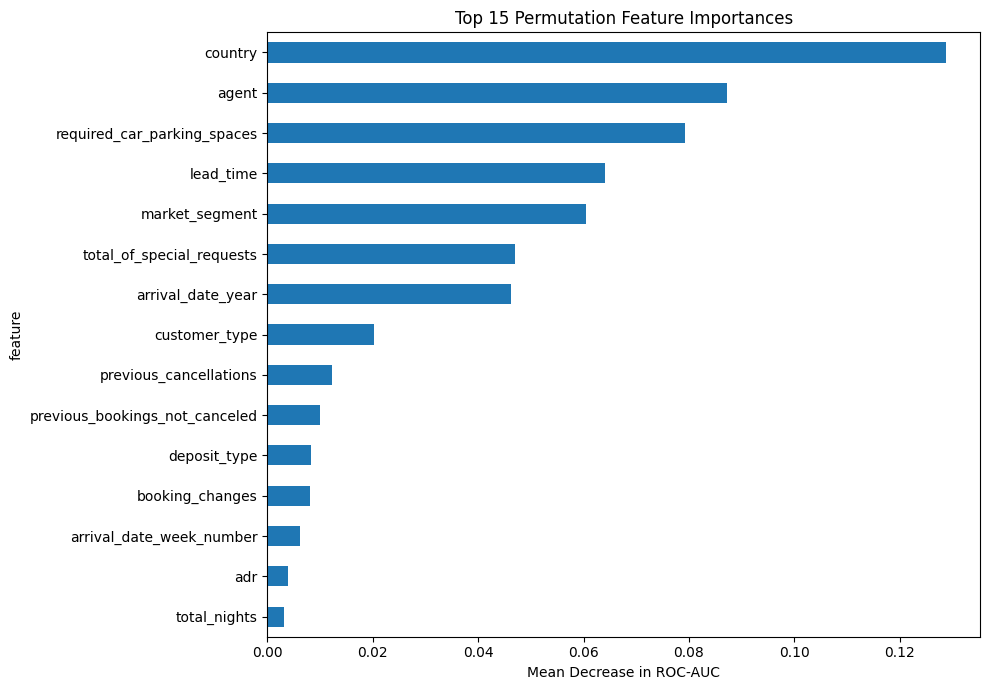

In [32]:
perm_df.head(15).plot(
    x="feature", y="importance_mean", kind="barh", figsize=(10, 7), legend=False
)
plt.xlabel("Mean Decrease in ROC-AUC")
plt.title("Top 15 Permutation Feature Importances")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("visuals/permutation_importance.png", dpi=150)
plt.show()

## 15. Save Final Model

In [33]:
import joblib

model_artifact = {
    "model": best_model,
    "threshold": best_threshold,
    "features": features
}

joblib.dump(model_artifact, "models/hotel_cancellation_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [34]:
artifact = joblib.load("models/hotel_cancellation_model.pkl")

loaded_model = artifact["model"]
loaded_threshold = artifact["threshold"]
loaded_features = artifact["features"]

print("Model loaded successfully.")
print("Threshold:", loaded_threshold)
print("Number of features:", len(loaded_features))

Model loaded successfully.
Threshold: 0.35
Number of features: 29


## 16. Example: Predicting a New Booking

In [35]:
def predict_booking(booking, model, threshold):
    booking_df = pd.DataFrame([booking])[loaded_features]
    probability = model.predict_proba(booking_df)[0, 1]
    return {
        "cancellation_probability": float(round(probability, 4)),
        "prediction": "Canceled" if probability >= threshold else "Not Canceled"
    }

In [36]:
sample_booking = X_test.iloc[0].to_dict()
print("Sample booking:", sample_booking)
print("Actual outcome:", "Canceled" if y_test.iloc[0] == 1 else "Not Canceled")
print(predict_booking(sample_booking, loaded_model, loaded_threshold))

Sample booking: {'lead_time': 21, 'arrival_date_year': 2016, 'arrival_date_week_number': 36, 'arrival_date_day_of_month': 29, 'stays_in_weekend_nights': 1, 'stays_in_week_nights': 3, 'adults': 2, 'children': 0.0, 'babies': 0, 'is_repeated_guest': 0, 'previous_cancellations': 0, 'previous_bookings_not_canceled': 0, 'booking_changes': 0, 'days_in_waiting_list': 0, 'adr': 124.25, 'required_car_parking_spaces': 0, 'total_of_special_requests': 2, 'total_nights': 4, 'total_guests': 2.0, 'hotel': 'City Hotel', 'arrival_date_month': 'August', 'meal': 'BB', 'country': 'DEU', 'market_segment': 'Online TA', 'distribution_channel': 'TA/TO', 'reserved_room_type': 'A', 'deposit_type': 'No Deposit', 'agent': '9', 'customer_type': 'Transient'}
Actual outcome: Not Canceled
{'cancellation_probability': 0.2113, 'prediction': 'Not Canceled'}
